# Blok 3 · Część 2 — Zespoły drzew: bagging, Random Forest, boosting

**Uczenie maszynowe w Pythonie** — Politechnika Gdańska, 2026

**Skąd przychodzimy (część 1):** pojedyncze drzewo nie wymaga skalowania ani imputacji, samo łapie nieliniowości i interakcje — ale jest **niestabilne**. Pięć drzew na pięciu próbkach hoteli nie zgadzało się co do ok. 38% rezerwacji, a zwykłe głosowanie było lepsze od każdego z nich.

**Dwie drogi naprawy:**
* **uśrednić wiele drzew** → mniejsza wariancja → *bagging*,
* **budować drzewa po kolei, każde poprawia błędy poprzednich** → mniejszy bias → *boosting*.

**Plan:**
1. Mądrość tłumu — kiedy uśrednianie działa
2. Bagging
3. Random Forest (+ ważność cech, kalibracja)
4. Boosting — idea
5. Boosting w praktyce: XGBoost (regularyzacja, ograniczenia monotoniczne, early stopping), LightGBM, CatBoost
6. Strategia strojenia: `RandomizedSearchCV`
7. Modele liniowe czy drzewiaste?

**Dane:** te same co w części 1 — hotele, California, kredyty (GMSC) i sinusoida.

## 0. Przygotowanie

Dane i funkcje pomocnicze — te same co w części 1. Dla kredytów funkcja `ocen` liczy dodatkowo **Brier** (bank używa PD (probability of default) wprost — wniosek z Zajęć 2).

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn import set_config
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer, SplineTransformer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.base import BaseEstimator, TransformerMixin

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
set_config(transform_output="pandas")

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (8, 5)
sns.set_theme(style="whitegrid")

# biblioteki boostingowe (CatBoost doinstaluje się sam, jeśli go brakuje)
import xgboost as xgb
import lightgbm as lgb
try:
    import catboost
except ImportError:                      # Colab: CatBoost nie jest preinstalowany
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "catboost"], check=True)
    import catboost

print("scikit-learn", sklearn.__version__, "| xgboost", xgb.__version__, "| lightgbm", lgb.__version__, "| catboost", catboost.__version__)

scikit-learn 1.9.1 | xgboost 3.4.1 | lightgbm 4.7.0 | catboost 1.2.10


In [2]:
URL = "https://raw.githubusercontent.com/ml-course-pg/ml-course-pg-2026/main/01-wprowadzenie/data/"

def wczytaj(nazwa):
    try:
        return pd.read_csv(f"../01-wprowadzenie/data/{nazwa}")
    except FileNotFoundError:
        return pd.read_csv(URL + nazwa)

TARGET = "SeriousDlqin2yrs"

def wczytaj_kredyty():
    try:
        from scipy.io import arff
        df = pd.DataFrame(arff.loadarff("../02-ocena-i-dane/data/give-me-some-credit")[0])
    except FileNotFoundError:
        from sklearn.datasets import fetch_openml
        df = fetch_openml(data_id=45577, as_frame=True).frame
    df[TARGET] = df[TARGET].map(lambda v: v.decode() if isinstance(v, bytes) else v).astype(int)
    return df

hotele = wczytaj("hotels.csv")
kalifornia = wczytaj("california_housing.csv")
kredyty_pelne = wczytaj_kredyty()
kredyty, _ = train_test_split(kredyty_pelne, train_size=30_000, stratify=kredyty_pelne[TARGET], random_state=RANDOM_STATE)
kredyty = kredyty.reset_index(drop=True)

CECHY_NUM = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights",
             "adults", "children", "babies", "is_repeated_guest",
             "previous_cancellations", "previous_bookings_not_canceled",
             "days_in_waiting_list", "adr",
             "required_car_parking_spaces", "total_of_special_requests"]
CECHY_KAT = ["hotel", "meal", "market_segment", "distribution_channel",
             "reserved_room_type", "deposit_type", "customer_type", "country", "agent"]

X_hot = hotele[CECHY_NUM + CECHY_KAT].copy()
X_hot["agent"] = hotele["agent"].fillna(0).astype(int).astype(str).replace("0", "brak")
X_hot["country"] = X_hot["country"].fillna("brak")
y_hot = hotele["is_canceled"]

kalifornia["BedrmsShare"] = kalifornia["AveBedrms"] / kalifornia["AveRooms"]
X_kal = kalifornia.drop(columns="MedHouseVal")
y_kal = kalifornia["MedHouseVal"]

X_kred = kredyty.drop(columns=TARGET)
y_kred = kredyty[TARGET]

cv_hot = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_kal = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_kred = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def preprocessing_drzewa():
    return ColumnTransformer(
        [("kategorie", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CECHY_KAT)],
        remainder="passthrough", verbose_feature_names_out=False)

OPOZNIENIA = ["NumberOfTime30-59DaysPastDueNotWorse", "NumberOfTime60-89DaysPastDueNotWorse", "NumberOfTimes90DaysLate"]

def kody_na_braki(X):
    X = X.copy()
    for c in OPOZNIENIA:
        X.loc[X[c] >= 96, c] = np.nan
    return X

class Winsoryzacja(BaseEstimator, TransformerMixin):
    def __init__(self, q=0.01):
        self.q = q
    def fit(self, X, y=None):
        A = np.asarray(X, dtype=float)
        self.dolne_ = np.nanquantile(A, self.q, axis=0)
        self.gorne_ = np.nanquantile(A, 1 - self.q, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.dolne_, self.gorne_)
    def set_output(self, *, transform=None):
        return self

In [3]:
TABELA = []

def ocen(nazwa, model, X, y, cv, metryka, zbior, pokaz=True, zapisz=True):
    metryki = [metryka] + (["neg_brier_score"] if zbior == "kredyty" else [])
    t0 = time.time()
    r = cross_validate(model, X, y, cv=cv, scoring=metryki, return_train_score=True, n_jobs=-1)
    znak = -1 if metryka.startswith("neg_") else 1
    wiersz = {"zbiór": zbior, "model": nazwa, "metryka": metryka.replace("neg_", ""),
              "walidacja": znak * r[f"test_{metryka}"].mean(), "± std": r[f"test_{metryka}"].std(),
              "trening": znak * r[f"train_{metryka}"].mean(), "czas CV [s]": time.time() - t0}
    if zbior == "kredyty":
        wiersz["Brier"] = -r["test_neg_brier_score"].mean()
    if zapisz:
        TABELA.append(wiersz)
    if pokaz:
        dod = f"   Brier: {wiersz['Brier']:.4f}" if zbior == "kredyty" else ""
        print(f"{nazwa:<48} {wiersz['metryka']}: {wiersz['walidacja']:.4f} ± {wiersz['± std']:.4f}"
              f"   (trening: {wiersz['trening']:.4f}){dod}   [{wiersz['czas CV [s]']:.1f} s]")
    return wiersz

Punkty odniesienia: najlepszy model liniowy z Zajęć 1–2 i nastrojone drzewo z części 1 (parametry z `GridSearchCV`).

In [4]:
lr_hotele = Pipeline([
    ("preprocessing", ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"),
                              FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), CECHY_NUM),
        ("kat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False), CECHY_KAT),
    ])),
    ("model", LogisticRegression(max_iter=2000)),
])
gam_kal = make_pipeline(StandardScaler(), SplineTransformer(n_knots=8, degree=3), Ridge(alpha=1.0))
lr_kredyty = make_pipeline(FunctionTransformer(kody_na_braki), SimpleImputer(strategy="median", add_indicator=True),
                           Winsoryzacja(0.01), StandardScaler(), LogisticRegression(max_iter=3000))

ocen("liniowy: regresja logistyczna (Zajęcia 1–2)", lr_hotele, X_hot, y_hot, cv_hot, "roc_auc", "hotele")
ocen("drzewo nastrojone (część 1)", make_pipeline(preprocessing_drzewa(),
     DecisionTreeClassifier(max_depth=12, min_samples_leaf=20, random_state=RANDOM_STATE)), X_hot, y_hot, cv_hot, "roc_auc", "hotele")
print()
ocen("liniowy: GAM splajny + Ridge (Zajęcia 1)", gam_kal, X_kal, y_kal, cv_kal, "neg_root_mean_squared_error", "kalifornia")
ocen("drzewo nastrojone (część 1)", DecisionTreeRegressor(min_samples_leaf=20, random_state=RANDOM_STATE),
     X_kal, y_kal, cv_kal, "neg_root_mean_squared_error", "kalifornia")
print()
ocen("liniowy: LR najlepsza z Zajęć 2", lr_kredyty, X_kred, y_kred, cv_kred, "average_precision", "kredyty")
ocen("drzewo nastrojone (część 1)", DecisionTreeClassifier(max_depth=8, min_samples_leaf=100, random_state=RANDOM_STATE),
     X_kred, y_kred, cv_kred, "average_precision", "kredyty");

liniowy: regresja logistyczna (Zajęcia 1–2)      roc_auc: 0.9095 ± 0.0057   (trening: 0.9164)   [1.3 s]
drzewo nastrojone (część 1)                      roc_auc: 0.8964 ± 0.0057   (trening: 0.9283)   [0.9 s]

liniowy: GAM splajny + Ridge (Zajęcia 1)         root_mean_squared_error: 0.6658 ± 0.0153   (trening: 0.6604)   [1.0 s]
drzewo nastrojone (część 1)                      root_mean_squared_error: 0.6145 ± 0.0172   (trening: 0.5085)   [1.1 s]

liniowy: LR najlepsza z Zajęć 2                  average_precision: 0.3542 ± 0.0145   (trening: 0.3547)   Brier: 0.0518   [1.0 s]
drzewo nastrojone (część 1)                      average_precision: 0.3341 ± 0.0164   (trening: 0.3720)   Brier: 0.0517   [0.2 s]


---
## 1. Mądrość tłumu — kiedy uśrednianie działa

Mamy $n$ modeli, każdy z wariancją błędu $\sigma^2$, a ich błędy są skorelowane współczynnikiem $\rho$. Wariancja **średniej** z tych modeli to:

$$\text{Var}(\text{średnia}) = \rho\,\sigma^2 + \frac{1-\rho}{n}\,\sigma^2$$

* Drugi składnik **znika**, gdy dokładamy modeli ($n \to \infty$).
* Pierwszy składnik **zostaje** — tylu modeli nie dołożymy, żeby go zbić. Uśrednianie pomaga tylko na tyle, na ile modele **mylą się różnie**.

Ten jeden wzór tłumaczy cały bagging.

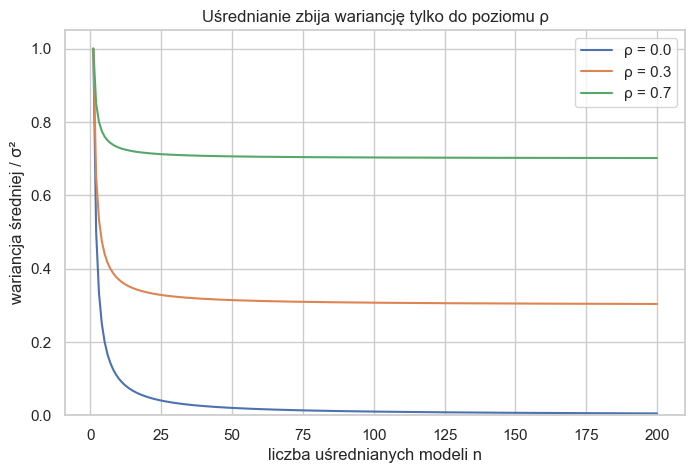

In [5]:
n = np.arange(1, 201)
for rho in [0.0, 0.3, 0.7]:
    plt.plot(n, rho + (1 - rho) / n, label=f"ρ = {rho}")
plt.xlabel("liczba uśrednianych modeli n"); plt.ylabel("wariancja średniej / σ²")
plt.title("Uśrednianie zbija wariancję tylko do poziomu ρ")
plt.ylim(0, 1.05); plt.legend(); plt.show()

---
## 2. Bagging

### 2.1 Bootstrap: wiele „różnych” zbiorów z jednego

Nie mamy wielu zbiorów danych — mamy jeden. **Bootstrap**: losujemy $N$ wierszy **ze zwracaniem** z $N$ wierszy. Część wierszy trafi kilka razy, część wcale.

In [6]:
rng = np.random.default_rng(RANDOM_STATE)
N = len(X_hot)
udzialy = [len(np.unique(rng.integers(0, N, size=N))) / N for _ in range(200)]
print(f"średnio w próbce bootstrap jest {np.mean(udzialy):.1%} unikalnych wierszy (teoria: 1 − 1/e ≈ 63.2%)")

średnio w próbce bootstrap jest 63.2% unikalnych wierszy (teoria: 1 − 1/e ≈ 63.2%)


**Bagging** (*bootstrap aggregating*):
1. Wylosuj $B$ próbek bootstrap.
2. Na każdej wytrenuj **głębokie** drzewo (bez przycinania — mały bias, duża wariancja; wariancję zaraz zbijemy).
3. Uśrednij predykcje (regresja) lub prawdopodobieństwa / głosy (klasyfikacja).

Na sinusoidzie z części 1:

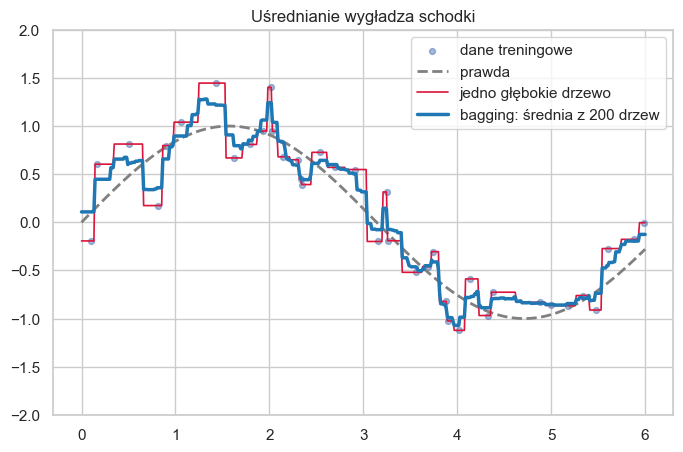

RMSE walidacja — jedno drzewo: 0.392   bagging: 0.326


In [7]:
from sklearn.ensemble import BaggingClassifier, BaggingRegressor

rng_s = np.random.default_rng(0)
Xs = np.sort(rng_s.uniform(0, 6, size=60)).reshape(-1, 1)
ys = np.sin(Xs).ravel() + rng_s.normal(0, 0.25, size=60)
Xs_tr, Xs_val, ys_tr, ys_val = train_test_split(Xs, ys, test_size=0.35, random_state=RANDOM_STATE)
siatka_s = np.linspace(0, 6, 500).reshape(-1, 1)

jedno = DecisionTreeRegressor(random_state=RANDOM_STATE).fit(Xs_tr, ys_tr)
bag = BaggingRegressor(DecisionTreeRegressor(), n_estimators=200, random_state=RANDOM_STATE).fit(Xs_tr, ys_tr)

plt.scatter(Xs_tr, ys_tr, s=18, alpha=0.5, label="dane treningowe")
plt.plot(siatka_s, np.sin(siatka_s), color="gray", ls="--", lw=2, label="prawda")
plt.plot(siatka_s, jedno.predict(siatka_s), color="crimson", lw=1.2, label="jedno głębokie drzewo")
plt.plot(siatka_s, bag.predict(siatka_s), color="tab:blue", lw=2.5, label="bagging: średnia z 200 drzew")
plt.ylim(-2, 2); plt.legend(); plt.title("Uśrednianie wygładza schodki")
plt.show()

from sklearn.metrics import root_mean_squared_error
print(f"RMSE walidacja — jedno drzewo: {root_mean_squared_error(ys_val, jedno.predict(Xs_val)):.3f}   "
      f"bagging: {root_mean_squared_error(ys_val, bag.predict(Xs_val)):.3f}")

### 2.2 Więcej drzew **nie** przeucza

Dokładamy drzewa jedno po drugim i patrzymy na walidację:

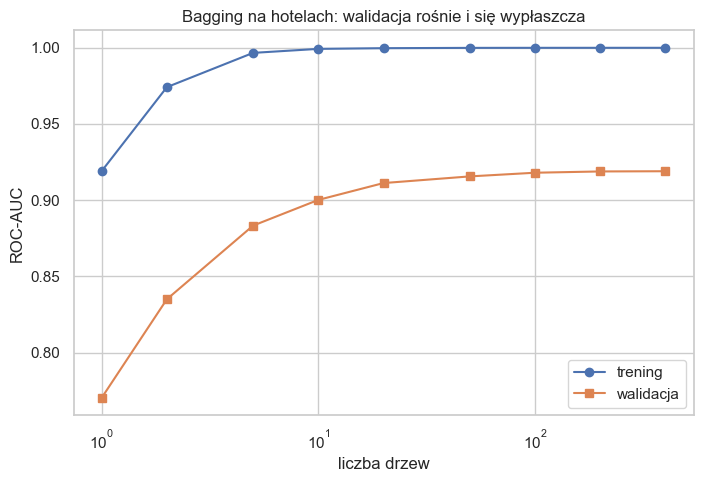

,0,1,2,3,4,5,6,7,8
drzew,1.0000,2.0000,5.0000,10.0000,20.0000,50.0000,100.0000,200.0000,400.0000
trening,0.9190,0.9741,0.9965,0.9992,0.9996,0.9998,0.9999,0.9999,0.9999
walidacja,0.7704,0.8350,0.8833,0.9001,0.9112,0.9155,0.9180,0.9188,0.9189


In [8]:
from sklearn.metrics import roc_auc_score

Xh_tr, Xh_val, yh_tr, yh_val = train_test_split(X_hot, y_hot, test_size=0.25, stratify=y_hot, random_state=RANDOM_STATE)
pre_h = preprocessing_drzewa().fit(Xh_tr)
Xh_tr_k, Xh_val_k = pre_h.transform(Xh_tr), pre_h.transform(Xh_val)

bag_h = BaggingClassifier(DecisionTreeClassifier(), n_estimators=1, warm_start=True, random_state=RANDOM_STATE, n_jobs=-1)
liczby = [1, 2, 5, 10, 20, 50, 100, 200, 400]
krzywa = []
for k in liczby:
    bag_h.set_params(n_estimators=k).fit(Xh_tr_k, yh_tr)
    krzywa.append({"drzew": k, "trening": roc_auc_score(yh_tr, bag_h.predict_proba(Xh_tr_k)[:, 1]),
                   "walidacja": roc_auc_score(yh_val, bag_h.predict_proba(Xh_val_k)[:, 1])})
krzywa = pd.DataFrame(krzywa)
plt.plot(krzywa["drzew"], krzywa["trening"], "o-", label="trening")
plt.plot(krzywa["drzew"], krzywa["walidacja"], "s-", label="walidacja")
plt.xscale("log"); plt.xlabel("liczba drzew"); plt.ylabel("ROC-AUC")
plt.title("Bagging na hotelach: walidacja rośnie i się wypłaszcza"); plt.legend(); plt.show()
krzywa.round(4).T

* Z jednego drzewa do kilkudziesięciu — duży skok. Potem **plateau**.
* Walidacja **nie spada** przy 400 drzewach — dokładanie drzew zmniejsza tylko składnik $(1-\rho)\sigma^2/n$. Więcej drzew = dłuższe liczenie, **nie** przeuczenie.
* Trening ~1.0 to nie alarm: każde drzewo widziało ok. 63% wierszy i je „zapamiętało”. Uczciwą ocenę daje walidacja — albo…

### 2.3 OOB — darmowa walidacja

Każde drzewo **nie widziało** ok. 37% wierszy (*out-of-bag*). Dla każdego wiersza możemy uśrednić tylko te drzewa, które go nie widziały — i dostajemy ocenę „jak na walidacji”, **bez** dodatkowego podziału i bez CV.

In [9]:
bag_oob = make_pipeline(preprocessing_drzewa(),
                        BaggingClassifier(DecisionTreeClassifier(), n_estimators=200, oob_score=True, random_state=RANDOM_STATE, n_jobs=-1))
bag_oob.fit(X_hot, y_hot)
print(f"accuracy OOB (jeden trening):   {bag_oob[-1].oob_score_:.4f}")
ocen("bagging 200 drzew", make_pipeline(preprocessing_drzewa(),
     BaggingClassifier(DecisionTreeClassifier(), n_estimators=200, random_state=RANDOM_STATE)),
     X_hot, y_hot, cv_hot, "accuracy", "hotele", zapisz=False);

accuracy OOB (jeden trening):   0.8475
bagging 200 drzew                                accuracy: 0.8458 ± 0.0090   (trening: 0.9972)   [2.7 s]


OOB jest bardzo blisko wyniku 5-krotnej CV, a kosztuje **jeden** trening zamiast pięciu. Przydatne przy dużych danych. Do porównań wariantów nadal używamy CV na tych samych foldach — OOB to szybki podgląd.

---
## 3. Random Forest

### 3.1 Problem baggingu: drzewa są do siebie podobne

W hotelach jest jedna bardzo silna cecha — `deposit_type`. Każde drzewo w baggingu widzi wszystkie cechy, więc **każde** zaczyna od tego samego pytania. Drzewa są do siebie podobne → wysokie $\rho$ → uśrednianie pomaga mniej, niż mogłoby.

**Pomysł Random Forest:** przy **każdym podziale** drzewo może wybierać tylko spośród **losowego podzbioru cech** (`max_features`). Czasem `deposit_type` nie będzie dostępny — i drzewo musi znaleźć inną drogę. Drzewa stają się **różnorodne** → niższe $\rho$.

In [10]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

nazwy = list(pre_h.get_feature_names_out())
las = RandomForestClassifier(n_estimators=200, max_features="sqrt", random_state=RANDOM_STATE, n_jobs=-1).fit(Xh_tr_k, yh_tr)
bag_200 = BaggingClassifier(DecisionTreeClassifier(), n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1).fit(Xh_tr_k, yh_tr)

def korzenie(drzewa):
    return pd.Series([nazwy[d.tree_.feature[0]] for d in drzewa]).value_counts(normalize=True).head(4).round(2).to_dict()

def srednia_korelacja(drzewa, X):
    P = np.array([d.predict_proba(X.values)[:, 1] for d in drzewa[:50]])
    K = np.corrcoef(P)
    return K[np.triu_indices_from(K, k=1)].mean()

print("pierwsze pytanie w drzewach:")
print("   bagging:      ", korzenie(bag_200.estimators_))
print("   Random Forest:", korzenie(las.estimators_))
print(f"\nśrednia korelacja predykcji między drzewami (ρ):  bagging {srednia_korelacja(bag_200.estimators_, Xh_val_k):.2f}"
      f"   Random Forest {srednia_korelacja(las.estimators_, Xh_val_k):.2f}")
sr_drzewo = lambda drzewa: np.mean([roc_auc_score(yh_val, d.predict_proba(Xh_val_k.values)[:, 1]) for d in drzewa[:50]])
print(f"ROC-AUC pojedynczego drzewa (średnio):  bagging {sr_drzewo(bag_200.estimators_):.4f}   Random Forest {sr_drzewo(las.estimators_):.4f}")
print(f"ROC-AUC całego zespołu:                 bagging {roc_auc_score(yh_val, bag_200.predict_proba(Xh_val_k)[:, 1]):.4f}"
      f"   Random Forest {roc_auc_score(yh_val, las.predict_proba(Xh_val_k)[:, 1]):.4f}")

pierwsze pytanie w drzewach:
   bagging:       {'deposit_type': 1.0}
   Random Forest: {'deposit_type': 0.2, 'country': 0.18, 'total_of_special_requests': 0.14, 'lead_time': 0.14}

średnia korelacja predykcji między drzewami (ρ):  bagging 0.56   Random Forest 0.50
ROC-AUC pojedynczego drzewa (średnio):  bagging 0.7750   Random Forest 0.7647
ROC-AUC całego zespołu:                 bagging 0.9188   Random Forest 0.9220


W baggingu wszystkie drzewa zaczynają od `deposit_type`. W lesie korzenie są różne, korelacja między drzewami spada — i las, mimo że jego pojedyncze drzewa są średnio **słabsze**, jako całość jest **lepszy**. Dokładnie to mówi wzór z sekcji 1: niższe ρ jest warte więcej niż odrobinę lepsze pojedyncze modele.

### 3.2 Hiperparametry — co naprawdę ma znaczenie

| hiperparametr | znaczenie | rada |
|---|---|---|
| `n_estimators` | liczba drzew | **więcej = lepiej lub tak samo**, tylko wolniej; 200–500 zwykle wystarcza. Nie strojone — tylko „wystarczająco dużo” |
| `max_features` | ile cech losujemy przy każdym podziale | **główne pokrętło** (kontroluje ρ)|
| `min_samples_leaf` | min. obserwacji w liściu | 1 zwykle OK; większe wartości → gładsze, lepiej skalibrowane p (ważne przy rzadkiej klasie) |
| `max_depth` | głębokość | zwykle bez limitu — wariancję zbija uśrednianie |
| `class_weight` | wagi klas | jak w LR — uwaga na kalibrację (Zajęcia 2) |
| `n_jobs=-1` | wszystkie rdzenie | drzewa są niezależne → liczą się równolegle |

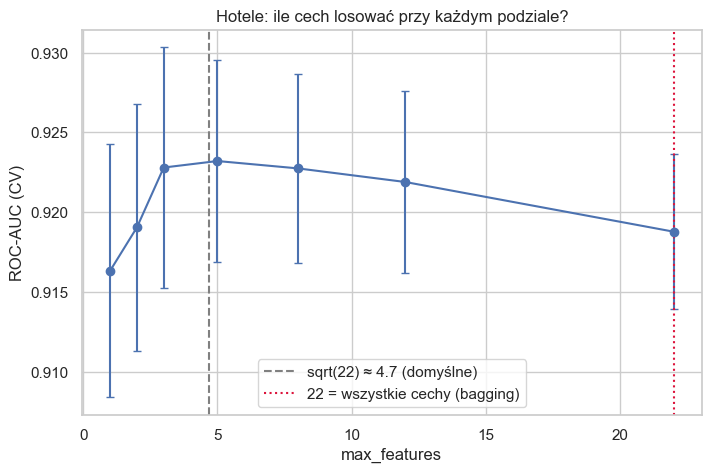

In [11]:
wyniki_mf = []
for mf in [1, 2, 3, 5, 8, 12, 22]:
    r = cross_validate(make_pipeline(preprocessing_drzewa(), RandomForestClassifier(n_estimators=150, max_features=mf, random_state=RANDOM_STATE)),
                       X_hot, y_hot, cv=cv_hot, scoring="roc_auc", n_jobs=-1)
    wyniki_mf.append({"max_features": mf, "ROC-AUC": r["test_score"].mean(), "std": r["test_score"].std()})
wyniki_mf = pd.DataFrame(wyniki_mf)
plt.errorbar(wyniki_mf["max_features"], wyniki_mf["ROC-AUC"], yerr=wyniki_mf["std"], fmt="o-", capsize=3)
plt.axvline(np.sqrt(22), color="gray", ls="--", label="sqrt(22) ≈ 4.7 (domyślne)")
plt.axvline(22, color="crimson", ls=":", label="22 = wszystkie cechy (bagging)")
plt.xlabel("max_features"); plt.ylabel("ROC-AUC (CV)"); plt.title("Hotele: ile cech losować przy każdym podziale?"); plt.legend(); plt.show()

* Za mało cech (1–2) — drzewa są zbyt losowe i słabe.
* Wszystkie 22 cechy (= bagging) — wynik niższy niż przy kilku cechach. Różnica jest mała w porównaniu z odchyleniem między foldami, ale kierunek jest zgodny z teorią.
* Domyślne `"sqrt"` jest blisko optimum, co zdarza się często. W hotelach zysk z losowania cech jest umiarkowany — bywa większy, gdy w danych jest wiele skorelowanych, silnych cech.

### 3.3 Las na trzech zbiorach

In [12]:
ocen("Random Forest (500 drzew)", make_pipeline(preprocessing_drzewa(),
     RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE)), X_hot, y_hot, cv_hot, "roc_auc", "hotele")
ocen("Random Forest (300 drzew, max_features=0.33)",
     RandomForestRegressor(n_estimators=300, max_features=0.33, random_state=RANDOM_STATE),
     X_kal, y_kal, cv_kal, "neg_root_mean_squared_error", "kalifornia")
ocen("Random Forest (300 drzew, min_samples_leaf=20)",
     RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=RANDOM_STATE),
     X_kred, y_kred, cv_kred, "average_precision", "kredyty");

Random Forest (500 drzew)                        roc_auc: 0.9236 ± 0.0065   (trening: 0.9998)   [2.2 s]
Random Forest (300 drzew, max_features=0.33)     root_mean_squared_error: 0.5002 ± 0.0080   (trening: 0.1854)   [5.3 s]
Random Forest (300 drzew, min_samples_leaf=20)   average_precision: 0.3712 ± 0.0165   (trening: 0.5144)   Brier: 0.0505   [5.1 s]


Las wyraźnie bije pojedyncze drzewo **i** najlepsze modele liniowe na wszystkich trzech zbiorach

### 3.4 Ważność cech MDI (Mean Decrease in Impurity)

Las daje „za darmo” `feature_importances_` — **MDI** (*mean decrease in impurity*): o ile łącznie podziały na danej cesze zmniejszyły Gini, uśrednione po drzewach i znormalizowane do sumy 1.

Sprawdźmy to w stylu Zajęć 2: **dokładamy kolumnę czystego szumu** — ważność prawdziwej cechy powinna być wyraźnie większa niż szumu.

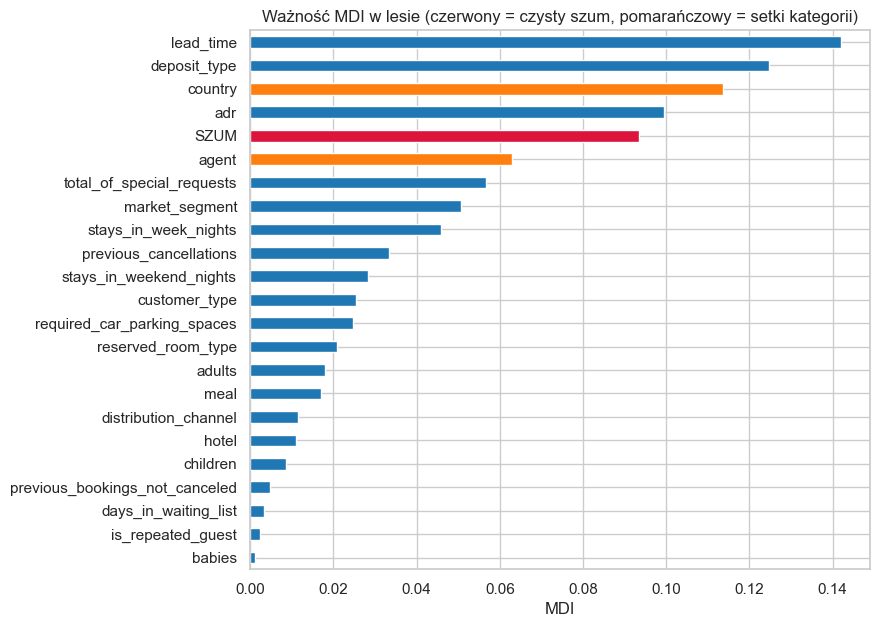

SZUM jest na miejscu 5 z 23


In [13]:
X_hot_szum = X_hot.copy()
X_hot_szum["SZUM"] = np.random.default_rng(0).normal(size=len(X_hot))

las_szum = make_pipeline(preprocessing_drzewa(), RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)).fit(X_hot_szum, y_hot)
waznosc = pd.Series(las_szum[-1].feature_importances_, index=las_szum[0].get_feature_names_out()).sort_values()

kolory = ["crimson" if c == "SZUM" else ("tab:orange" if c in ["country", "agent"] else "tab:blue") for c in waznosc.index]
waznosc.plot.barh(color=kolory, figsize=(8, 7))
plt.title("Ważność MDI w lesie (czerwony = czysty szum, pomarańczowy = setki kategorii)")
plt.xlabel("MDI"); plt.show()
print(f"SZUM jest na miejscu {list(waznosc.index[::-1]).index('SZUM') + 1} z {len(waznosc)}")

Losowy szum ma większą ważność niż **większość prawdziwych cech**. Trzy pułapki MDI:
1. **Faworyzuje cechy o wielu unikalnych wartościach** — ciągłe (szum, `adr`, `lead_time`) i kategorie z setkami poziomów (`country`, `agent`) mają więcej możliwych progów, więc częściej „przypadkiem” znajdą użyteczny podział.
2. **Liczona na treningu** — mierzy, jak drzewa użyły cechy do dopasowania danych treningowych, a nie, jak cecha pomaga na nowych danych. Las zapamiętuje szum, więc szum dostaje ważność.
3. **Skorelowane cechy dzielą się ważnością** — dwie prawie identyczne cechy dostaną po połowie, choć każda z osobna jest ważna.

**Do czego MDI się nadaje:** szybki, zgrubny przegląd („`deposit_type`, `lead_time`, `country` dominują”). 

**Do czego MDI się nie nadaje:** do twardych wniosków i selekcji cech. Metody, które mierzą wpływ cech uczciwie (na danych walidacyjnych), poznamy na Zajęciach 5.

### 3.5 Kalibracja lasu

Las uśrednia głosy drzew, więc rzadko daje p bliskie 0 lub 1 — prawdopodobieństwa mają tendencję do **„ściągania do środka”**. Sprawdzamy narzędziami z Zajęć 2 — na hotelach (predykcje spoza próby z `cross_val_predict`):

jedno głębokie drzewo        Brier: 0.1982   ROC-AUC: 0.7907
Random Forest                Brier: 0.1050   ROC-AUC: 0.9231
Random Forest + isotonic     Brier: 0.1043   ROC-AUC: 0.9235


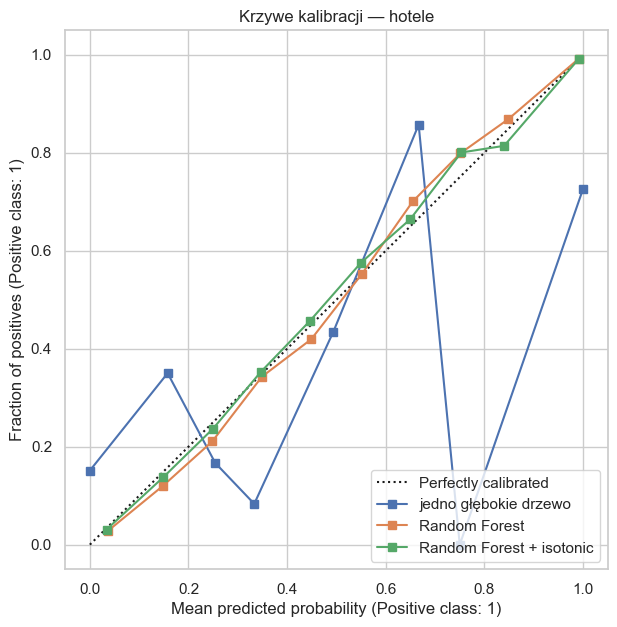

In [14]:
from sklearn.calibration import CalibrationDisplay, CalibratedClassifierCV
from sklearn.metrics import brier_score_loss

las_hot = make_pipeline(preprocessing_drzewa(), RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))
warianty = {
    "jedno głębokie drzewo": make_pipeline(preprocessing_drzewa(), DecisionTreeClassifier(random_state=RANDOM_STATE)),
    "Random Forest": las_hot,
    "Random Forest + isotonic": CalibratedClassifierCV(las_hot, method="isotonic", cv=5),
}
fig, ax = plt.subplots(figsize=(7, 7))
for nazwa, m in warianty.items():
    p = cross_val_predict(m, X_hot, y_hot, cv=cv_hot, method="predict_proba")[:, 1]
    print(f"{nazwa:<28} Brier: {brier_score_loss(y_hot, p):.4f}   ROC-AUC: {roc_auc_score(y_hot, p):.4f}")
    CalibrationDisplay.from_predictions(y_hot, p, n_bins=10, ax=ax, name=nazwa)
ax.set_title("Krzywe kalibracji — hotele"); plt.show()

* **Jedno głębokie drzewo** — katastrofa: liście są czyste, więc p to prawie zawsze 0 albo 1. 
* **Las** — dużo lepiej, ale widać lekkie „S”: w przedziale 0.6–0.9 las jest **zbyt ostrożny** (prawdziwy odsetek anulowań jest wyższy niż przewidywane p).
* **Kalibracja** (`CalibratedClassifierCV`, jak na Zajęciach 2) prostuje krzywą i poprawia Briera, **nie** ruszając rankingu (ROC-AUC prawie bez zmian). 

---
## 4. Boosting — idea

Bagging trenuje drzewa **niezależnie** i je uśrednia. Boosting robi coś zupełnie innego: trenuje **małe** drzewa **po kolei**, a każde kolejne uczy się **tego, czego poprzednie jeszcze nie umieją**.

### 4.1 Boosting „ręcznie” — na resztach

Dla regresji:
1. Start: predykcja = średnia $y$.
2. Policz **reszty**: $r = y - \text{predykcja}$ — to, czego model jeszcze nie wyjaśnił.
3. Dopasuj **małe** drzewo (np. głębokość 2) do reszt.
4. Dodaj je do modelu, ale **małym krokiem**: predykcja += `learning_rate` × drzewo.
5. Wróć do kroku 2.

Cały algorytm to kilka linijek:

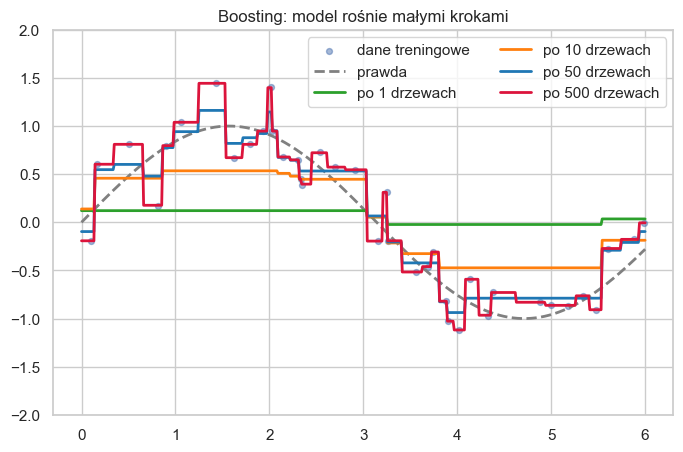

In [15]:
def boosting_recznie(X_tr, y_tr, X_ewaluacja, n_drzew, learning_rate=0.1, glebokosc=2):
    pred_tr = np.full(len(y_tr), y_tr.mean())          # krok 1: start od średniej
    pred_ew = np.full(len(X_ewaluacja), y_tr.mean())
    historia = []
    for _ in range(n_drzew):
        reszty = y_tr - pred_tr                        # krok 2: czego jeszcze nie umiemy
        drzewo = DecisionTreeRegressor(max_depth=glebokosc).fit(X_tr, reszty)   # krok 3
        pred_tr += learning_rate * drzewo.predict(X_tr)                         # krok 4
        pred_ew += learning_rate * drzewo.predict(X_ewaluacja)
        historia.append(pred_ew.copy())
    return historia

historia = boosting_recznie(Xs_tr, ys_tr, siatka_s, n_drzew=500)

plt.scatter(Xs_tr, ys_tr, s=18, alpha=0.5, label="dane treningowe")
plt.plot(siatka_s, np.sin(siatka_s), color="gray", ls="--", lw=2, label="prawda")
for k, kolor in [(1, "tab:green"), (10, "tab:orange"), (50, "tab:blue"), (500, "crimson")]:
    plt.plot(siatka_s, historia[k - 1], color=kolor, lw=2, label=f"po {k} drzewach")
plt.ylim(-2, 2); plt.legend(ncol=2); plt.title("Boosting: model rośnie małymi krokami"); plt.show()

Po 1 drzewie model prawie nic nie umie. Po 50 — dobrze odtwarza sinusoidę. Po 500 — zaczyna gonić szum. **Tu, inaczej niż w baggingu, dokładanie drzew może przeuczyć:**

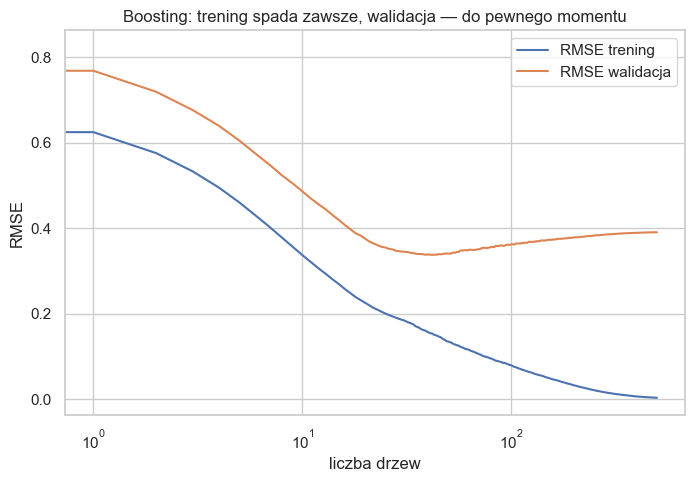

In [16]:
hist_tr = boosting_recznie(Xs_tr, ys_tr, Xs_tr, n_drzew=500)
hist_val = boosting_recznie(Xs_tr, ys_tr, Xs_val, n_drzew=500)
plt.plot([root_mean_squared_error(ys_tr, p) for p in hist_tr], label="RMSE trening")
plt.plot([root_mean_squared_error(ys_val, p) for p in hist_val], label="RMSE walidacja")
plt.xscale("log"); plt.xlabel("liczba drzew"); plt.ylabel("RMSE"); plt.legend()
plt.title("Boosting: trening spada zawsze, walidacja — do pewnego momentu"); plt.show()

Znowu litera **U** — liczba drzew w boostingu to pokrętło złożoności, które trzeba nastroić (albo zatrzymać trening w porę — *early stopping*, sekcja 5.4).

`learning_rate` (*shrinkage*) to długość kroku: mniejszy krok → potrzeba więcej drzew, ale model zwykle generalizuje lepiej.

### 4.3 Bagging vs boosting

| | **Bagging** | **Boosting** |
|---|---|---|
| jak trenujemy drzewa | **niezależnie**, równolegle | **sekwencyjnie**, każde poprawia poprzednie |
| jakie drzewa | **głębokie** (mały bias, duża wariancja) | **płytkie** (duży bias, mała wariancja) |
| co zmniejsza | **wariancję** (przez "uśrednianie")| **bias** (przez korekcję błędu poprzedniego modelu)|
| więcej drzew | bezpieczne — tylko wolniej | może **przeuczyć** → stroimy lub *early stopping* |
| strojenie | łatwe, domyślne zwykle OK | **konieczne** — domyślne bywają złe |
| typowy wynik na danych tabelarycznych | bardzo dobry | zwykle **najlepszy** |

---
## 5. Boosting w praktyce

W praktyce nie piszemy pętli sami. Głównym narzędziem będzie **XGBoost** (Extreme Gradient Boosting)— standard w branży i na Kaggle. Ma interfejs zgodny ze sklearn: `XGBClassifier` / `XGBRegressor` działają w `Pipeline`, `cross_validate` i `GridSearchCV` jak każdy inny model.

> W sklearn jest też `HistGradientBoostingClassifier` — ten sam typ modelu, bez dodatkowej instalacji. Przyda się, gdy XGBoost nie chce się zainstalować.

### 5.1 XGBoost na surowych kredytach — z `NaN`

**Bez imputera, bez winsoryzacji, bez skalowania.** XGBoost przy każdym podziale uczy się, w którą stronę wysyłać braki.

In [17]:
# n_jobs=1 w modelu, bo równolegle liczymy foldy CV (unikamy „walki” o rdzenie)
ocen("XGBoost: ustawienia domyślne", xgb.XGBClassifier(n_jobs=1, random_state=RANDOM_STATE),
     X_kred, y_kred, cv_kred, "average_precision", "kredyty")
ocen("XGBoost: 300 drzew, lr=0.05, max_depth=4",
     xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, n_jobs=1, random_state=RANDOM_STATE),
     X_kred, y_kred, cv_kred, "average_precision", "kredyty");

XGBoost: ustawienia domyślne                     average_precision: 0.3151 ± 0.0192   (trening: 0.8443)   Brier: 0.0550   [1.3 s]
XGBoost: 300 drzew, lr=0.05, max_depth=4         average_precision: 0.3669 ± 0.0156   (trening: 0.5349)   Brier: 0.0510   [1.1 s]


**Lekcja:** XGBoost na ustawieniach domyślnych (`learning_rate=0.3`, `max_depth=6`) jest **gorszy od regresji logistycznej** — duży krok i głębokie drzewa przy rzadkiej klasie to przeuczenie (patrz trening vs walidacja). Mniejszy krok i płytsze drzewa → od razu najlepszy wynik w tabeli. Boosting **trzeba stroić** — systematycznie zrobimy to w sekcji 6.

### 5.2 Regularyzacja i losowość w XGBoost

XGBoost ma kilka regularyzacji znanych z Zajęć 1 — tylko zakładanych na drzewa:

| parametr | co robi | analogia |
|---|---|---|
| `reg_lambda` | kara L2 na wartości w liściach | Ridge |
| `reg_alpha` | kara L1 na wartości w liściach | Lasso |
| `gamma` | minimalny zysk, żeby podział się „opłacał” | `min_impurity_decrease` / `ccp_alpha` |
| `min_child_weight` | minimalna „masa” w liściu | `min_samples_leaf` |
| `subsample` | każde drzewo widzi losową część **wierszy** | bagging |
| `colsample_bytree` | każde drzewo widzi losową część **cech** | `max_features` w Random Forest |

Zróbmy celowo przeuczony model (duży krok, głębokie drzewa) i sprawdźmy każdą opcje **osobno**:

In [18]:
baza = dict(n_estimators=300, learning_rate=0.1, max_depth=8, n_jobs=1, random_state=RANDOM_STATE)
for nazwa, dodatki in [
    ("przeuczony: lr=0.1, max_depth=8", {}),
    ("+ reg_lambda=50", dict(reg_lambda=50)),
    ("+ reg_alpha=5", dict(reg_alpha=5)),
    ("+ gamma=1", dict(gamma=1)),
    ("+ min_child_weight=20", dict(min_child_weight=20)),
    ("+ subsample=0.7, colsample_bytree=0.7", dict(subsample=0.7, colsample_bytree=0.7)),
    ("+ wszystko naraz", dict(reg_lambda=10, min_child_weight=20, gamma=1, subsample=0.7, colsample_bytree=0.7)),
]:
    ocen(f"XGB {nazwa}", xgb.XGBClassifier(**baza, **dodatki), X_kred, y_kred, cv_kred, "average_precision", "kredyty", zapisz=False)

XGB przeuczony: lr=0.1, max_depth=8              average_precision: 0.3091 ± 0.0169   (trening: 0.9679)   Brier: 0.0554   [0.6 s]
XGB + reg_lambda=50                              average_precision: 0.3505 ± 0.0175   (trening: 0.6870)   Brier: 0.0519   [1.4 s]
XGB + reg_alpha=5                                average_precision: 0.3413 ± 0.0160   (trening: 0.7559)   Brier: 0.0525   [1.3 s]
XGB + gamma=1                                    average_precision: 0.3496 ± 0.0144   (trening: 0.7086)   Brier: 0.0519   [0.3 s]
XGB + min_child_weight=20                        average_precision: 0.3422 ± 0.0151   (trening: 0.6248)   Brier: 0.0525   [1.3 s]
XGB + subsample=0.7, colsample_bytree=0.7        average_precision: 0.3084 ± 0.0114   (trening: 0.9858)   Brier: 0.0557   [0.7 s]
XGB + wszystko naraz                             average_precision: 0.3493 ± 0.0111   (trening: 0.5776)   Brier: 0.0519   [0.6 s]


* **Kary i minimum w liściu** (`reg_lambda`, `reg_alpha`, `gamma`, `min_child_weight`) wyraźnie zmniejszają rozjazd trening–walidacja i poprawiają walidację.
* **Sama losowość** (`subsample`, `colsample_bytree`) tutaj **nie pomaga** — każde drzewo jest dalej za głębokie i za mocne. Losowość działa najlepiej jako dodatek do rozsądnie ustawionego modelu, a nie jako jedyny ratunek.
* Żadna metoda regularyzacji osobno nie dorównuje po prostu **mniejszemu krokowi i płytszym drzewom** z 5.1 (ok. 0.368).

Wniosek: parametry boostingu **działają razem** — trzeba je stroić łącznie, a nie po kolei ręcznie (sekcja 6).

### 5.3 Ograniczenia monotoniczne — model, któremu bank może zaufać

Weźmy jednego klienta z dobrym modelem z 5.1 i zmieniajmy **tylko jego dochód**:

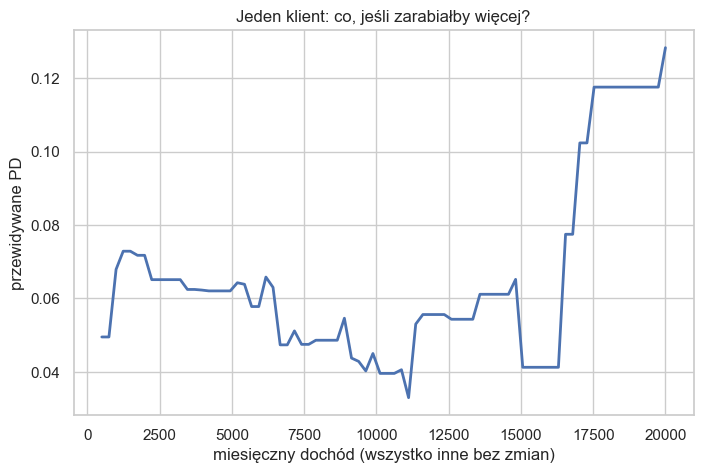

u 198 z 200 klientów wzrost dochodu w którymś miejscu PODNOSI PD o więcej niż 0.2 pp


In [19]:
P_XGB = dict(n_estimators=300, learning_rate=0.05, max_depth=4, n_jobs=1, random_state=RANDOM_STATE)
xgb_zwykly = xgb.XGBClassifier(**P_XGB).fit(X_kred, y_kred)

dochody = np.linspace(500, 20_000, 80)

def co_jesli(model, klient, cecha="MonthlyIncome", wartosci=dochody):
    Z = pd.concat([klient] * len(wartosci), ignore_index=True)
    Z[cecha] = wartosci
    return model.predict_proba(Z)[:, 1]

klient = X_kred[X_kred["MonthlyIncome"].notna()].iloc[[0]]
plt.plot(dochody, co_jesli(xgb_zwykly, klient), lw=2)
plt.xlabel("miesięczny dochód (wszystko inne bez zmian)"); plt.ylabel("przewidywane PD")
plt.title("Jeden klient: co, jeśli zarabiałby więcej?"); plt.show()

ile_razy = sum((np.diff(co_jesli(xgb_zwykly, X_kred[X_kred["MonthlyIncome"].notna()].iloc[[i]])) > 0.002).any() for i in range(200))
print(f"u {ile_razy} z 200 klientów wzrost dochodu w którymś miejscu PODNOSI PD o więcej niż 0.2 pp")

Wyższy dochód **podnosi** ryzyko? Analityk ryzyka czy regulator takiego modelu nie zaakceptuje, a klientowi nie da się tego wytłumaczyć („dostał Pan gorszą ofertę, bo zarabia Pan więcej”). Przyczyna: w rzadkich obszarach danych (wysokie dochody, mało defaultów) model dopasował się do szumu — wysoka wariancja z części 1, tylko schowana w zespole drzew.

**Rozwiązanie:** wpisujemy w model **wiedzę domenową** — `monotone_constraints`: `+1` = ryzyko może tylko rosnąć z cechą, `-1` = tylko maleć, cechy bez jasnej teorii (`DebtRatio`, liczba kredytów) zostawiamy bez ograniczeń.

XGBoost: ograniczenia monotoniczne               average_precision: 0.3634 ± 0.0144   (trening: 0.4675)   Brier: 0.0512   [0.4 s]


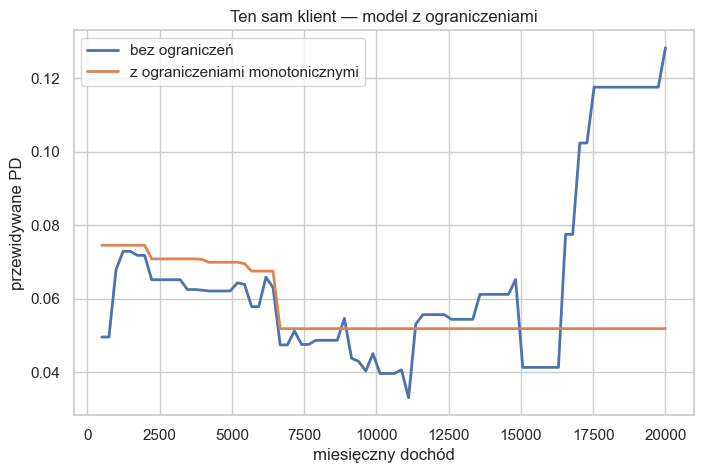

In [20]:
MONOTONICZNOSC = {
    "RevolvingUtilizationOfUnsecuredLines": 1,      # większe wykorzystanie limitów -> większe ryzyko
    "NumberOfTime30-59DaysPastDueNotWorse": 1,      # więcej opóźnień -> większe ryzyko
    "NumberOfTime60-89DaysPastDueNotWorse": 1,
    "NumberOfTimes90DaysLate": 1,
    "MonthlyIncome": -1,                            # wyższy dochód -> mniejsze ryzyko
    "age": -1,                                      # starszy -> mniejsze ryzyko (typowe w danych kredytowych)
}
# kody 96/98 zamieniamy na NaN (krok z Zajęć 2) — ograniczenia mają dotyczyć liczby opóźnień, nie kodów
xgb_monotoniczny = make_pipeline(FunctionTransformer(kody_na_braki),
                                 xgb.XGBClassifier(**P_XGB, monotone_constraints=MONOTONICZNOSC))

ocen("XGBoost: ograniczenia monotoniczne", xgb_monotoniczny, X_kred, y_kred, cv_kred, "average_precision", "kredyty")

xgb_monotoniczny.fit(X_kred, y_kred)
plt.plot(dochody, co_jesli(xgb_zwykly, klient), lw=2, label="bez ograniczeń")
plt.plot(dochody, co_jesli(xgb_monotoniczny, klient), lw=2, label="z ograniczeniami monotonicznymi")
plt.xlabel("miesięczny dochód"); plt.ylabel("przewidywane PD"); plt.legend()
plt.title("Ten sam klient — model z ograniczeniami"); plt.show()

**Za ułamek PR-AUC (różnica w granicach jednego odchylenia między foldami) dostajemy model, którego zachowanie zgadza się ze zdrowym rozsądkiem i da się obronić przed działem ryzyka.** W bankowości, ubezpieczeniach czy medycynie to często warunek wdrożenia.

To samo istnieje w LightGBM (`monotone_constraints`), w sklearn (`monotonic_cst` — w `HistGradientBoosting*`, a od wersji 1.4 także w drzewach i lesie).

> Wykres „jeden klient, zmieniamy jedną cechę” to tu tylko prosty eksperyment. Formalne narzędzia do takich analiz poznamy na Zajęciach 5.

### 5.4 Early stopping — `eval_set` to walidacja, **nigdy test**

Zamiast stroić liczbę drzew, można trenować „do skutku” i **zatrzymać się**, gdy wynik na zbiorze walidacyjnym przestaje rosnąć:

zatrzymano po 61 drzewach z 3000 (PR-AUC na zbiorze do zatrzymania: 0.3732)


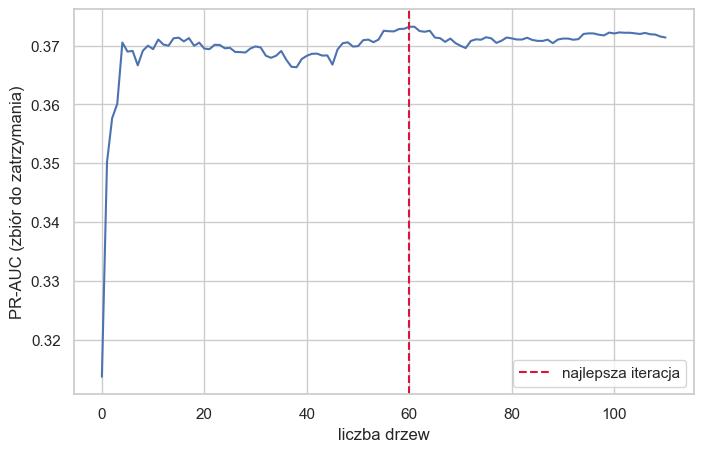

In [21]:
# zbiór do zatrzymania wydzielamy z TRENINGU — test (gdybyśmy go mieli) zostaje nietknięty
X_es_tr, X_es_val, y_es_tr, y_es_val = train_test_split(X_kred, y_kred, test_size=0.2, stratify=y_kred, random_state=RANDOM_STATE)

xgb_es = xgb.XGBClassifier(n_estimators=3000, learning_rate=0.05, max_depth=4,
                           early_stopping_rounds=50, eval_metric="aucpr", n_jobs=-1, random_state=RANDOM_STATE)
xgb_es.fit(X_es_tr, y_es_tr, eval_set=[(X_es_val, y_es_val)], verbose=False)
print(f"zatrzymano po {xgb_es.best_iteration + 1} drzewach z 3000 (PR-AUC na zbiorze do zatrzymania: {xgb_es.best_score:.4f})")

krzywa_es = xgb_es.evals_result()["validation_0"]["aucpr"]
plt.plot(krzywa_es); plt.axvline(xgb_es.best_iteration, color="crimson", ls="--", label="najlepsza iteracja")
plt.xlabel("liczba drzew"); plt.ylabel("PR-AUC (zbiór do zatrzymania)"); plt.legend(); plt.show()

⚠️ **Pułapka leakage (Zajęcia 2):** zbiór w `eval_set` **wpływa na model** (decyduje, ile ma drzew) — więc wynik na nim jest optymistyczny, tak jak `best_score_` po strojeniu. Podanie tu **zbioru testowego** to klasyczny błąd: test przestaje być testem.

Dlatego w tym kursie w CV i strojeniu traktujemy `n_estimators` jako zwykły hiperparametr (razem z `learning_rate`), a early stopping — jako szybki sposób, żeby **oszacować**, ile drzew potrzeba.

### 5.5 LightGBM

LightGBM to ten sam pomysł. Główna różnica: drzewa rosną **liść po liściu** — zawsze dzielony jest liść, który daje największy zysk, zamiast całego poziomu naraz do max_depth jak w przypadku XGBoost. Złożoność kontroluje `num_leaves` (nie `max_depth`). Zwykle jest **bardzo szybki** na dużych danych.

In [22]:
porownanie = {
    "Random Forest (300 drzew)": RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=RANDOM_STATE),
    "XGBoost (300 drzew)": xgb.XGBClassifier(**P_XGB),
    "LightGBM (300 drzew)": lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15,
                                               n_jobs=1, random_state=RANDOM_STATE, verbose=-1),
}
for nazwa, m in porownanie.items():
    ocen(nazwa, m, X_kred, y_kred, cv_kred, "average_precision", "kredyty", zapisz=(nazwa.startswith("LightGBM")))

Random Forest (300 drzew)                        average_precision: 0.3712 ± 0.0165   (trening: 0.5144)   Brier: 0.0505   [5.2 s]
XGBoost (300 drzew)                              average_precision: 0.3669 ± 0.0156   (trening: 0.5349)   Brier: 0.0510   [0.4 s]
LightGBM (300 drzew)                             average_precision: 0.3652 ± 0.0156   (trening: 0.6012)   Brier: 0.0510   [0.6 s]


Wyniki XGBoost i LightGBM są w granicach szumu — na danych tabelarycznych tej wielkości wybór biblioteki zwykle **nie** jest najważniejszą decyzją. Różnice zaczynają się przy milionach wierszy (szybkość) i w szczegółach (kategorie, ograniczenia, wdrożenie).

### 5.6 CatBoost

**CatBoost** to ten sam pomysł co XGBoost i LightGBM, ale z dwiema różnicami:

**1. Drzewa symetryczne.** Na każdym poziomie drzewa **wszystkie węzły zadają to samo pytanie** (np. „`lead_time` ≤ 30?”). Pojedyncze drzewo jest prostsze, co działa jak regularyzacja — stąd dobre ustawienia domyślne.

**2. Kategorie jako surowy tekst** (`cat_features`). W środku CatBoost robi to samo co `TargetEncoder` z Zajęć 2 — zamienia kategorię na średni target — i tak samo pilnuje, żeby target nie przeciekł: dla każdego wiersza liczy średnią tylko z wierszy „wcześniejszych” w losowej kolejności.

**Kiedy którą bibliotekę?**
* **XGBoost** — dane głównie liczbowe; najwięcej kontroli nad regularyzacją.
* **LightGBM** — bardzo duże dane albo liczy się czas.
* **CatBoost** — dużo kolumn kategorycznych albo mało czasu na strojenie.

**Demo na hotelach, aby największy atut CatBoost był wudoczny:** `country` (ok. 100 wartości) i `agent` (ok. 200). Porównujemy XGBoosta z kodowaniem z Zajęć 2 (OneHot, `TargetEncoder`) z CatBoostem na **surowych** kolumnach tekstowych.

In [23]:
from sklearn.preprocessing import TargetEncoder
from catboost import CatBoostClassifier

KAT_MALE = [c for c in CECHY_KAT if c not in ["country", "agent"]]
P_HOT = dict(n_estimators=300, learning_rate=0.05, max_depth=6, n_jobs=1, random_state=RANDOM_STATE)

def xgb_z_kodowaniem(koder_wysokie):
    return make_pipeline(
        ColumnTransformer([("male", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), KAT_MALE),
                           ("wysokie", koder_wysokie, ["country", "agent"])],
                          remainder="passthrough", verbose_feature_names_out=False),
        xgb.XGBClassifier(**P_HOT))

ocen("XGBoost + OneHot(min_frequency=10) dla country/agent",
     xgb_z_kodowaniem(OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False)),
     X_hot, y_hot, cv_hot, "roc_auc", "hotele", zapisz=False)
ocen("XGBoost + TargetEncoder dla country/agent",
     xgb_z_kodowaniem(TargetEncoder(random_state=RANDOM_STATE)), X_hot, y_hot, cv_hot, "roc_auc", "hotele")

# CatBoost: surowe kolumny tekstowe, bez żadnego enkodera
# uwaga: cat_features podajemy jako KROTKĘ (tuple) — z listą sklearn nie umie sklonować modelu w CV
catboost_hot = CatBoostClassifier(iterations=300, learning_rate=0.1, depth=6, cat_features=tuple(CECHY_KAT),
                                  random_seed=RANDOM_STATE, thread_count=1, verbose=0,
                                  allow_writing_files=False)
ocen("CatBoost: surowe kategorie (bez enkodera)", catboost_hot, X_hot, y_hot, cv_hot, "roc_auc", "hotele");

XGBoost + OneHot(min_frequency=10) dla country/agent roc_auc: 0.9280 ± 0.0037   (trening: 0.9570)   [0.4 s]
XGBoost + TargetEncoder dla country/agent        roc_auc: 0.9263 ± 0.0039   (trening: 0.9586)   [0.2 s]
CatBoost: surowe kategorie (bez enkodera)        roc_auc: 0.9289 ± 0.0028   (trening: 0.9556)   [3.7 s]


* Wszystkie trzy warianty są w granicach szumu — na hotelach wszystkie dają ok. 0.93 ROC-AUC, dużo więcej niż regresja logistyczna (ok. 0.91).
* Wartość CatBoosta to tu **wygoda i bezpieczeństwo**: zero enkoderów i wbudowana ochrona przed przeciekiem targetu. Przy tysiącach kategorii i małych grupach przewaga bywa większa.

### 5.7 „Wielka trójka” — ściąga

| | **XGBoost** | **LightGBM** | **CatBoost** |
|---|---|---|---|
| wyróżnik | regularyzacja (`reg_lambda`, `reg_alpha`, `gamma`), dojrzały ekosystem, GPU | drzewa liść po liściu, szybkość na dużych danych | natywne kategorie z ochroną przed przeciekiem, symetryczność, dobre ustawienia domyślne |
| braki `NaN` | natywnie | natywnie | natywnie |
| kategorie | `enable_categorical=True` + typ `category` w pandas | typ `category` w pandas | `cat_features=(...)` — surowy tekst |
| ograniczenia monotoniczne | `monotone_constraints` | `monotone_constraints` | `monotone_constraints` |

**Ten sam parametr — różne nazwy:**

| znaczenie | XGBoost | LightGBM | CatBoost | sklearn `HistGradientBoosting` |
|---|---|---|---|---|
| liczba drzew | `n_estimators` | `n_estimators` | `iterations` | `max_iter` |
| długość kroku | `learning_rate` | `learning_rate` | `learning_rate` | `learning_rate` |
| złożoność drzewa | `max_depth` | `num_leaves` | `depth` | `max_leaf_nodes` |
| min. w liściu | `min_child_weight` | `min_child_samples` | `min_data_in_leaf` | `min_samples_leaf` |
| kara L2 | `reg_lambda` | `reg_lambda` | `l2_leaf_reg` | `l2_regularization` |
| losowanie wierszy | `subsample` | `subsample` (+ `subsample_freq`) | `subsample` | — |
| losowanie cech | `colsample_bytree` | `colsample_bytree` | `rsm` | `max_features` |

---
## 6. Strategia strojenia: `RandomizedSearchCV`

XGBoost ma kilka ważnych hiperparametrów naraz. Siatka z 5 wartościami dla każdego z 7 parametrów to $5^7 = 78\,125$ kombinacji — a z 5 foldami CV ok. 390 tys. treningów. Nierealne.

**`RandomizedSearchCV`** losuje `n_iter` kombinacji z **rozkładów**. Dlaczego to działa lepiej niż siatka? Zwykle tylko 2–3 parametry mają duże znaczenie. Siatka marnuje budżet na powtarzanie tych samych wartości ważnego parametru (zmieniając tylko nieważne), a losowanie przy tym samym budżecie sprawdza **znacznie więcej różnych wartości każdego parametru**.

Dla `learning_rate` i kar liczy się, **ile razy** wartość się zmienia: krok 0.02 jest dwa razy dłuższy niż 0.01, a 0.29 to prawie to samo co 0.28. Zwykłe losowanie z zakresu 0.01–0.3 rzadko trafiałoby w małe wartości. Dlatego losujemy z rozkładu **`loguniform`**, który daje każdemu rzędowi wielkości tyle samo szans.

In [24]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint, uniform

rozklady = {
    "n_estimators":     randint(100, 800),
    "learning_rate":    loguniform(0.01, 0.3),
    "max_depth":        randint(2, 8),
    "min_child_weight": loguniform(1, 50),
    "subsample":        uniform(0.6, 0.4),        # od 0.6 do 1.0
    "colsample_bytree": uniform(0.5, 0.5),        # od 0.5 do 1.0
    "reg_lambda":       loguniform(0.1, 50),
    "gamma":            loguniform(1e-3, 5),
}
t0 = time.time()
rs = RandomizedSearchCV(xgb.XGBClassifier(n_jobs=1, random_state=RANDOM_STATE), rozklady, n_iter=20,
                        cv=cv_kred, scoring="average_precision", random_state=RANDOM_STATE, n_jobs=-1)
rs.fit(X_kred, y_kred)
print(f"czas: {time.time() - t0:.0f} s   najlepszy PR-AUC (CV): {rs.best_score_:.4f}")
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in rs.best_params_.items()})

(pd.DataFrame(rs.cv_results_).sort_values("rank_test_score")
 [["mean_test_score", "std_test_score", "param_learning_rate", "param_n_estimators", "param_max_depth"]]
 .head(6).round(4))

czas: 4 s   najlepszy PR-AUC (CV): 0.3758
{'colsample_bytree': np.float64(0.9826), 'gamma': np.float64(0.176), 'learning_rate': np.float64(0.0256), 'max_depth': 6, 'min_child_weight': np.float64(23.0626), 'n_estimators': 164, 'reg_lambda': np.float64(0.1102), 'subsample': np.float64(0.7694)}


,mean_test_score,std_test_score,param_learning_rate,param_n_estimators,param_max_depth
9,0.3758,0.0129,0.0256,164,6
10,0.3757,0.0116,0.0105,774,4
15,0.3740,0.0108,0.0130,677,4
3,0.3734,0.0116,0.0221,662,7
13,0.3731,0.0112,0.0239,114,4
5,0.3717,0.0125,0.0219,554,5


Podobne wyniki ale **wzorzec**: najlepsze mają mały `learning_rate` i dużo drzew, płytkie drzewa.

**Praktyczna kolejność strojenia boostingu:**
1. Ustaw rozsądny `learning_rate` (0.05–0.1) i dobierz **liczbę drzew** (early stopping albo CV).
2. Stroisz **złożoność drzewa**: `max_depth` / `num_leaves`, `min_child_weight`.
3. Stroisz **losowość i kary**: `subsample`, `colsample_bytree`, `reg_lambda`, `gamma`.
4. Na koniec: **mniejszy `learning_rate` + proporcjonalnie więcej drzew**.

### 6.1 `best_score_` jest optymistyczny

Wybraliśmy **maksimum** z 20 wyników CV — część tej „najlepszości” to szczęście w losowaniu (to samo zjawisko co z wieloma porównaniami na Zajęciach 2). Uczciwe oszacowanie dają:
* **zbiór testowy użyty raz** — po całym strojeniu (workflow z Zajęć 1),
* **nested CV** — strojenie wewnątrz każdego foldu zewnętrznej CV:

```
zewnętrzna CV (ocena)      ┌ fold 1: [ strojenie: RandomizedSearchCV z wewnętrzną CV ] → wynik na foldzie 1
5 foldów                   ├ fold 2: [ strojenie ...                                   ] → wynik na foldzie 2
                           └ ...                                                         → średnia ± std = uczciwa ocena CAŁEJ procedury
```
W kodzie to jedna linijka: `cross_validate(RandomizedSearchCV(...), X, y, cv=cv_zewnetrzna)` — ale kosztuje 5× więcej obliczeń.

In [25]:
ocen("XGBoost nastrojony (RandomizedSearchCV)", rs.best_estimator_, X_kred, y_kred, cv_kred, "average_precision", "kredyty")
print("\n↑ te same foldy, na których stroiliśmy — więc wynik jest optymistyczny")

XGBoost nastrojony (RandomizedSearchCV)          average_precision: 0.3758 ± 0.0129   (trening: 0.4371)   Brier: 0.0504   [0.4 s]

↑ te same foldy, na których stroiliśmy — więc wynik jest optymistyczny


---
## 7. Modele liniowe czy drzewiaste?

Dopiszmy boosting dla hoteli i California i zbierzmy wszystko:

In [26]:
ocen("XGBoost (300 drzew, lr=0.05, max_depth=6)", make_pipeline(preprocessing_drzewa(), xgb.XGBClassifier(**P_HOT)),
     X_hot, y_hot, cv_hot, "roc_auc", "hotele")
ocen("XGBoost (500 drzew, lr=0.05, max_depth=6)",
     xgb.XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, n_jobs=1, random_state=RANDOM_STATE),
     X_kal, y_kal, cv_kal, "neg_root_mean_squared_error", "kalifornia")

final = (pd.DataFrame(TABELA).sort_values("zbiór", kind="stable")
         .set_index(["zbiór", "metryka", "model"]))
final.round(4)

XGBoost (300 drzew, lr=0.05, max_depth=6)        roc_auc: 0.9262 ± 0.0039   (trening: 0.9636)   [0.3 s]
XGBoost (500 drzew, lr=0.05, max_depth=6)        root_mean_squared_error: 0.4517 ± 0.0102   (trening: 0.2803)   [0.7 s]


walidacja  \
zbiór      metryka                 model                                                       
hotele     roc_auc                 liniowy: regresja logistyczna (Zajęcia 1–2)        0.9095   
                                   drzewo nastrojone (część 1)                        0.8964   
                                   Random Forest (500 drzew)                          0.9236   
                                   XGBoost + TargetEncoder dla country/agent          0.9263   
                                   CatBoost: surowe kategorie (bez enkodera)          0.9289   
                                   XGBoost (300 drzew, lr=0.05, max_depth=6)          0.9262   
kalifornia root_mean_squared_error liniowy: GAM splajny + Ridge (Zajęcia 1)           0.6658   
                                   drzewo nastrojone (część 1)                        0.6145   
                                   Random Forest (300 drzew, max_features=0.33)       0.5002   
                                   XGBoost (500 drzew, lr=0.05, max_depth=6)          0.4517   
kredyty    average_precision       liniowy: LR najlepsza z Zajęć 2                    0.3542   
                                   drzewo nastrojone (część 1)                        0.3341   
                                   Random Forest (300 drzew, min_samples_leaf=20)     0.3712   
                                   XGBoost: ustawienia domyślne                       0.3151   
                                   XGBoost: 300 drzew, lr=0.05, max_depth=4           0.3669   
                                   XGBoost: ograniczenia monotoniczne                 0.3634   
                                   LightGBM (300 drzew)                               0.3652   
                                   XGBoost nastrojony (RandomizedSearchCV)            0.3758   

                                                                                    ± std  \
zbiór      metryka                 model                                                    
hotele     roc_auc                 liniowy: regresja logistyczna (Zajęcia 1–2)     0.0057   
                                   drzewo nastrojone (część 1)                     0.0057   
                                   Random Forest (500 drzew)                       0.0065   
                                   XGBoost + TargetEncoder dla country/agent       0.0039   
                                   CatBoost: surowe kategorie (bez enkodera)       0.0028   
                                   XGBoost (300 drzew, lr=0.05, max_depth=6)       0.0039   
kalifornia root_mean_squared_error liniowy: GAM splajny + Ridge (Zajęcia 1)        0.0153   
                                   drzewo nastrojone (część 1)                     0.0172   
                                   Random Forest (300 drzew, max_features=0.33)    0.0080   
                                   XGBoost (500 drzew, lr=0.05, max_depth=6)       0.0102   
kredyty    average_precision       liniowy: LR najlepsza z Zajęć 2                 0.0145   
                                   drzewo nastrojone (część 1)                     0.0164   
                                   Random Forest (300 drzew, min_samples_leaf=20)  0.0165   
                                   XGBoost: ustawienia domyślne                    0.0192   
                                   XGBoost: 300 drzew, lr=0.05, max_depth=4        0.0156   
                                   XGBoost: ograniczenia monotoniczne              0.0144   
                                   LightGBM (300 drzew)                            0.0156   
                                   XGBoost nastrojony (RandomizedSearchCV)         0.0129   

                                                                                   trening  \
zbiór      metryka                 model                                                     
hotele     roc_auc                 liniowy: regresja logistyczna (Zajęcia 1–2)      0.9164   
                   

**Co widzimy:**
* Na wszystkich trzech zbiorach zespoły drzew wygrywają z modelami liniowymi i z pojedynczym drzewem. Boosting jest najlepszy w California i w hotelach; w kredytach las, XGBoost i LightGBM są w granicach szumu.
* Największa różnica w **California** (geografia = interakcje), najmniejsza w **kredytach** — tam regresja logistyczna po dobrym przygotowaniu danych traci do boostingu niewiele.
* Koszt: czas, mniejsza przejrzystość, duży rozjazd trening–walidacja.

### Kiedy który?

| wybierz **model liniowy**, gdy… | wybierz **zespół drzew**, gdy… |
|---|---|
| danych jest mało (setki wierszy) | danych jest dużo (tysiące+) |
| zależności są w przybliżeniu liniowe / addytywne | są nieliniowości i interakcje |
| potrzebna jest **ekstrapolacja** (trend poza zakresem danych) | przewidujemy w zakresie znanych danych |
| potrzebujesz współczynników do raportu / regulatora | liczy się przede wszystkim jakość predykcji |
| dane są wysokowymiarowe i rzadkie (np. tekst, tysiące kolumn one-hot) | dane tabelaryczne o mieszanych typach, z brakami |

### Czego wymaga każda rodzina — ściąga przygotowania danych

| krok | model liniowy | drzewo / las / boosting |
|---|---|---|
| skalowanie | **tak** | nie |
| outliery w cechach | **tak** (winsoryzacja, log) | zwykle nie |
| braki | **imputacja** | natywnie (`NaN`) — imputacja opcjonalna |
| kategorie | **OneHot** / TargetEncoder | Ordinal / TargetEncoder / natywnie (CatBoost, LightGBM, XGBoost) |
| nieliniowości | ręcznie (splajny, interakcje) | same |
| błędy i kody w danych | **tak** | **tak** — dalej trzeba je zrozumieć (kody 96/98!) |

### Przepis na projekt

1. **Dummy** — punkt odniesienia.
2. **Regresja liniowa / logistyczna** z porządnym preprocessingiem — szybka, interpretowalna, mocny baseline.
3. **Random Forest** z domyślnymi ustawieniami — mało strojenia, zwykle duży skok.
4. **Boosting** (XGBoost / LightGBM / CatBoost) + `RandomizedSearchCV` — zwykle najlepszy wynik.
5. Wszystko na **tych samych foldach**, średnia ± std, **kalibracja** jeśli używamy p, test **raz** na końcu.

---
## Podsumowanie

**Trzy zasady:**
1. **Uśrednianie zbija wariancję, sekwencja zbija bias.** Las: głębokie, różnorodne drzewa, więcej drzew nie szkodzi. Boosting: małe drzewa, mały krok — liczbę drzew trzeba nastroić.
2. **Boosting bez strojenia potrafi przegrać z regresją logistyczną.** `RandomizedSearchCV` + CV na tych samych foldach.
3. **Mocny model nie zwalnia z myślenia.** Ważność MDI kłamie dla szumu, las bywa źle skalibrowany, a ograniczenia monotoniczne i zrozumienie kodów w danych decydują, czy model nadaje się do wdrożenia.

**Ściąga:**

| potrzeba | narzędzie |
|---|---|
| bagging | `BaggingClassifier/Regressor(DecisionTree...(), n_estimators=..., oob_score=True)` |
| las | `RandomForestClassifier/Regressor(n_estimators, max_features, min_samples_leaf, n_jobs=-1)` |
| ważność cech (zgrubnie) | `.feature_importances_` (MDI) — uwaga na pułapki |
| kalibracja | `CalibrationDisplay`, `CalibratedClassifierCV(model, method="isotonic" / "sigmoid")` |
| boosting | `xgb.XGBClassifier`, `lgb.LGBMClassifier`, `CatBoostClassifier(cat_features=(...))`, `HistGradientBoostingClassifier` |
| ograniczenia monotoniczne | `monotone_constraints={"cecha": 1 / -1}` |
| early stopping | `XGBClassifier(early_stopping_rounds=50)` + `fit(..., eval_set=[(X_val, y_val)])` — walidacja z treningu, **nie** test |
| strojenie | `RandomizedSearchCV(model, rozklady, n_iter=..., cv=cv, scoring=...)`, `loguniform`, `randint`, `uniform` |